# Build a BESSY II–inspired light-source lattice with Xsuite

**Intermediate tutorial · optics matching and radiation equilibrium · about 60–90 minutes with exercises**

We construct a **1.7 GeV electron storage ring from scratch**, using 16 identical
**double-bend achromat (DBA) cells** in a 240 m ring. The scale and nominal working
point come from BESSY II. The magnet sequence is a simplified teaching design,
not a reconstruction of the real machine. No external lattice files or MAD-X are needed.

Each cell has two dipoles, **one central focusing quadrupole**, and three quadrupoles
on each outer side. The extra outer knob lets us match a sensible straight-section
beta while choosing the stronger focusing of a light-source lattice.

The design sequence is: define magnet families → match a periodic achromat → assemble
and survey the ring → correct chromaticity → add RF focusing → compute radiation
integrals → find the damped 6D equilibrium and beam sizes.

The toy uses **15 m cells, 5.6 m magnet-free straights, and phase advances of
401.4° / 153.45° per cell**. Every straight has βx = 1.2 m and βy ≈ 3.2 m.
Real BESSY II has alternating high- and low-beta straights and a more elaborate
magnet layout. Our calculated emittance is about **15.4 nm at 1.7 GeV**; it is not
BESSY II's measured or design emittance.

Insertion devices, magnet errors, coupling, collective effects and physical apertures
are not included. A successful linear match does not establish nonlinear acceptance
or beam lifetime.

**Prerequisites:** Twiss parameters, dispersion, tunes, chromaticity and basic Python.
Run the notebook from top to bottom. When changing geometry or design parameters,
restart and run all cells to rebuild the derived lines.

## 1. Setup and conventions

Use a Python environment with `xsuite`, `numpy`, `scipy`, `pandas`, `matplotlib`,
`jupyterlab` and `ipykernel`. This notebook was validated with Xtrack 0.111.6 and
Xobjects 0.6.10; the first cell prints the versions in your kernel.
If needed, install packages in a separate cell with
`%pip install xsuite numpy scipy pandas matplotlib jupyterlab ipykernel`, then restart the kernel.
The first Xsuite calculation may take longer if tracking kernels need compilation.

Lengths are in metres, angles in radians, particle energies in eV, quadrupole `k1`
in m⁻² and sextupole `k2` in m⁻³. Emittances below are **geometric**, not normalized.
We first use `twiss4d()` with radiation off, so RF focusing is excluded from the optics match.

In [1]:
%matplotlib inline
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.constants import c, hbar, m_e
from IPython.display import display
import xtrack as xt

plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'font.size': 11})
for package in ['xtrack', 'xobjects', 'numpy', 'scipy']:
    print(f'{package}: {metadata.version(package)}')

xtrack: 0.111.6
xobjects: 0.6.10
numpy: 2.4.6
scipy: 1.17.0


## 2. Define magnet families and a symmetric cell

The [published BESSY II design](https://proceedings.jacow.org/p93/PDF/PAC1993_1474.PDF)
provides our reference scale: 1.7 GeV, 240 m, 16 DBA cells, 32 bends and nominal
ring tunes 17.84 / 6.82. BESSY II's reported straight-section waists include
βx = βy = 1.2 m in low-beta sections and βx = 15 m, βy = 4.5 m in high-beta sections
([2011 optics paper](https://accelconf.web.cern.ch/ipac2011/papers/thpc155.pdf)).
We use identical cells with βx = 1.2 m; βy is determined by the match.

Each bend turns the reference trajectory through $\theta_b = 2\pi/(2N_c)$.
Our 0.85 m sector dipoles have no quadrupole gradient or additional pole-face angles.
Xsuite's `Bend` sets its dipole field from the reference curvature by default.

Four quadrupole families provide four matching knobs: **Q1, Q2, Q3 and QC**.
QC is the single focusing quadrupole between the bends. Each outer group contains
Q1–Q2–Q3, allowing us to fix the straight-centre βx as well as both tunes and dispersion.
Q1 is a weak trim in the default solution, but is an independent matching knob.
Two sextupole families are initially off.

The half-cell runs from the centre of a straight to the entrance of QC:

`straight centre — 2.8 m drift — Q1 — Q2 — Q3 — B — SD — SF`

The full cell is `half_cell + QC + mirrored_half_cell`. QC is one physical 0.30 m
quadrupole, not duplicated in the half-cells. There are seven quadrupoles per cell.
Neighbouring cells join their end drifts into a **5.6 m magnet-free straight**.
The `-half_cell` syntax reverses element order without reversing magnet polarities.

The starting strengths lie near the required stable optics branch. They are an
initial guess for matching, not the published BESSY II magnet settings.

In [2]:
energy_eV = 1.7e9
n_cells = 16
qx_target, qy_target = 17.84, 6.82
beta_x_straight = 1.2
rf_voltage = 1.5e6

env = xt.Environment()
env.set_particle_ref('electron', energy0=energy_eV)
env.vars({
    'l_bend': 0.85,
    'theta_bend': 2 * np.pi / (2 * n_cells),
    'kq1': 0.01,
    'kq2': 3.92,
    'kq3': -3.50,
    'kqc': 2.93,
    'ksf': 0.0,
    'ksd': 0.0,
})

# Three outer quadrupoles, plus one central QC per cell.
for name, length in [('dss', 2.8), ('d03', 0.3), ('d05', 0.5),
                     ('d09', 0.9), ('d025', 0.25)]:
    env.new(name, xt.Drift, length=length)
for name in ['q1', 'q2', 'q3', 'qc']:
    env.new(name, xt.Quadrupole, length=0.30, k1='k' + name)
env.new('bend', xt.Bend, length='l_bend', angle='theta_bend')
env.new('sf', xt.Sextupole, length=0.15, k2='ksf')
env.new('sd', xt.Sextupole, length=0.15, k2='ksd')

half_cell = env.new_line(components=[
    'dss', 'q1', 'd025', 'q2', 'd025', 'q3', 'd05', 'bend',
    'd03', 'sd', 'd09', 'sf', 'd03',
])
cell = env.new_line(components=[
    env.new('ss', xt.Marker),
    half_cell, 'qc', -half_cell,
    env.new('cell_end', xt.Marker),
])
assert list(cell.element_names).count('qc') == 1
assert np.count_nonzero(cell.get_table().element_type == 'Quadrupole') == 7
np.testing.assert_allclose(cell.get_length(), 15.0)
print(f'Cell length: {cell.get_length():.3f} m')
print(f'Bend angle: {np.degrees(env["theta_bend"]):.3f} degrees')
cell.get_table().show(cols=['s', 'element_type'])

Cell length: 15.000 m
Bend angle: 11.250 degrees
name                   s element_type
ss                     0 Marker      
dss::0                 0 Drift       
q1::0                2.8 Quadrupole  
d025::0              3.1 Drift       
q2::0               3.35 Quadrupole  
d025::1             3.65 Drift       
q3::0                3.9 Quadrupole  
d05::0               4.2 Drift       
bend::0              4.7 Bend        
d03::0              5.55 Drift       
sd::0               5.85 Sextupole   
d09::0                 6 Drift       
sf::0                6.9 Sextupole   
d03::1              7.05 Drift       
qc                  7.35 Quadrupole  
d03::2              7.65 Drift       
sf::1               7.95 Sextupole   
d09::1               8.1 Drift       
sd::1                  9 Sextupole   
d03::3              9.15 Drift       
bend::1             9.45 Bend        
d05::1              10.3 Drift       
q3::1               10.8 Quadrupole  
d025::2             11.1 Drift       
q

In [3]:
tw_seed = cell.twiss4d()
print(f'Seed cell phase advances / 2π: {tw_seed.qx:.5f}, {tw_seed.qy:.5f}')
print(f'Seed dispersion at straight centre: {tw_seed["dx", "ss"]:.5f} m')

Seed cell phase advances / 2π: 1.11600, 0.42969
Seed dispersion at straight centre: 0.00073 m


## 3. Match the periodic achromat and source-point beta

For identical cells the ring tunes are $Q_x=N_c\mu_x/(2\pi)$ and
$Q_y=N_c\mu_y/(2\pi)$. Use the full cell phase advances **in turns**;
do not discard the integer part of the horizontal cell tune.

We vary four quadrupole strengths to impose four conditions:

| Target | Purpose |
|---|---|
| Cell `qx = 17.84 / 16 = 1.115` | Horizontal ring tune from the reference design |
| Cell `qy = 6.82 / 16 = 0.42625` | Vertical ring tune from the reference design |
| `dx = 0` at `ss` | Make the straight achromatic |
| `betx = 1.2 m` at `ss` | Keep a moderate source-point beta |

QC controls the achromatic two-bend section; the outer groups provide the extra
focusing freedom. Mirror symmetry makes $\alpha_x$, $\alpha_y$ and $D'_x$ vanish
at the straight centre. We verify these after matching rather than adding redundant targets.
The vertical source-point beta is not fixed and comes out near 3.2 m.

The cell phase advances are **401.4° horizontally and 153.45° vertically**.
A full achromat contains several focusing sections, so its accumulated phase can
exceed 360°. The plot below shows the accumulated phase explicitly. These tunes
are a reference for the toy; its nonlinear acceptance has not been optimized.

For a waist in a drift, $\beta(s)=\beta^*+s^2/\beta^*$.
With βx* = 1.2 m and a 2.8 m half-straight, βx reaches about 7.7 m at the first
quadrupole. Thus the stronger phase advance does not require a 30 cm source-point waist.

`solve=False` lets us inspect the residuals before running the optimizer. More
examples are in the [Xsuite matching guide](https://xsuite.readthedocs.io/en/latest/match.html).

In [4]:
optics_match = cell.match(
    solve=False,
    method='4d',
    vary=xt.VaryList(['kq1', 'kq2', 'kq3', 'kqc'], step=1e-5, limits=[-8, 8]),
    targets=[
        xt.TargetSet(qx=qx_target / n_cells, qy=qy_target / n_cells, tol=1e-8),
        xt.TargetSet(dx=0, at='ss', tol=1e-8),
        xt.TargetSet(betx=beta_x_straight, at='ss', tol=1e-6),
    ],
)
optics_match.target_status()
optics_match.solve()
optics_match.target_status()
optics_match.vary_status()

Target status:               
id state tag     tol_met       residue   current_val    target_val description                                 
0  ON    qx        False    0.00100497         1.116         1.115 'qx', val=1.115, tol=1e-08, weight=10       
1  ON    qy        False    0.00343735      0.429687       0.42625 'qy', val=0.42625, tol=1e-08, weight=10     
2  ON    ss_dx     False   0.000726343   0.000726343             0 ('dx', 'ss'), val=0, tol=1e-08, weight=1 ...
3  ON    ss_betx   False   -0.00277013       1.19723           1.2 ('betx', 'ss'), val=1.2, tol=1e-06, weig ...
                                             


Optimize - start penalty: 0.03665                         


Matching: model call n. 10 penalty = 1.5677e-04              


Optimize - end penalty:  5.97105e-09                            


Target status:               
id state tag     tol_met       residue   current_val    target_val description                                 
0  ON    qx         True   1.78529e-10         1.115         1.115 'qx', val=1.115, tol=1e-08, weight=10       
1  ON    qy         True   5.45634e-10       0.42625       0.42625 'qy', val=0.42625, tol=1e-08, weight=10     
2  ON    ss_dx      True   1.62785e-10   1.62785e-10             0 ('dx', 'ss'), val=0, tol=1e-08, weight=1 ...
3  ON    ss_betx    True   2.11394e-10           1.2           1.2 ('betx', 'ss'), val=1.2, tol=1e-06, weig ...
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  kq1           -8    0.00856709           8          0.01         1e-05             1
1  ON        OK  kq2           -8        3.9177           8          3.92         1e-05             1
2  ON        OK  kq3           -8      -3.49493           8          -3.5 

Periodic achromat, source-point beta and symmetry checks passed.
Straight-centre βx = 1.200 m
Straight-centre βy = 3.224 m


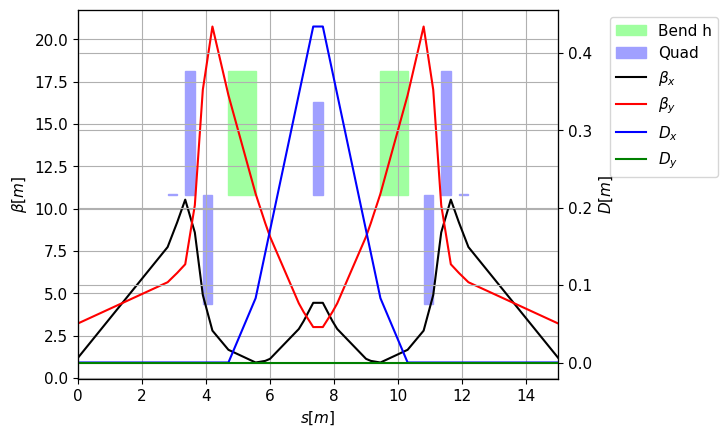

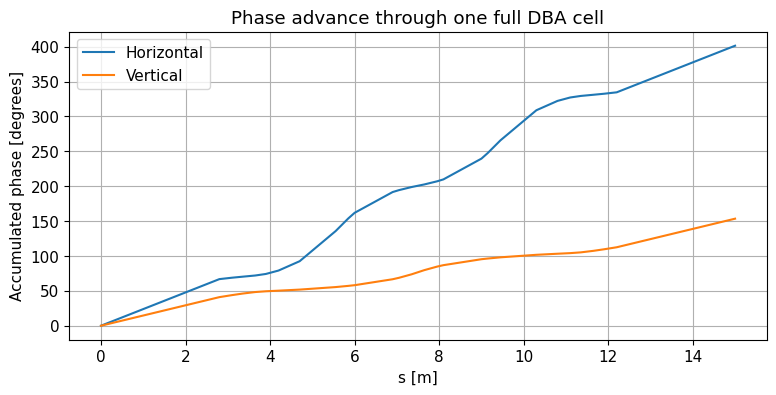

In [5]:
tw_cell = cell.twiss4d()
np.testing.assert_allclose([tw_cell.qx, tw_cell.qy],
                           np.array([qx_target, qy_target]) / n_cells, atol=1e-8, rtol=0)
np.testing.assert_allclose([tw_cell['dx', 'ss'], tw_cell['dpx', 'ss'],
                           tw_cell['alfx', 'ss'], tw_cell['alfy', 'ss']],
                          0, atol=1e-6)
np.testing.assert_allclose(tw_cell['betx', 'ss'], beta_x_straight, atol=1e-6, rtol=0)
assert tw_cell['bety', 'ss'] > 1.0  # Check that the other source-point beta is also moderate.
print('Periodic achromat, source-point beta and symmetry checks passed.')
print(f'Straight-centre βx = {tw_cell["betx", "ss"]:.3f} m')
print(f'Straight-centre βy = {tw_cell["bety", "ss"]:.3f} m')
tw_cell.plot()
plt.show()

fig, ax = plt.subplots()
ax.plot(tw_cell.s, 360 * tw_cell.mux, label='Horizontal')
ax.plot(tw_cell.s, 360 * tw_cell.muy, label='Vertical')
ax.set(xlabel='s [m]', ylabel='Accumulated phase [degrees]',
       title='Phase advance through one full DBA cell')
ax.legend()
plt.show()

**Read the plot:** dispersion is zero in the straight and rises inside the achromat.
The sextupoles lie in dispersive regions, at different ratios of $\beta_x/\beta_y$.
An off-momentum particle has $x\simeq D_x\delta$ there, so a sextupole supplies an
effective quadrupole term proportional to $k_2D_x\delta$. This is the mechanism for
chromaticity correction. The nonlinear kicks remain even after the linear
chromaticities have been corrected.

## 4. Assemble and survey the full ring

The RF cavity is a zero-length element at the centre of one straight. Its voltage
and frequency remain zero until we reach longitudinal dynamics.
`replace_all_repeated_elements()` gives each physical occurrence its own element,
while preserving the expressions that connect magnets to common family strengths.
This is useful before slicing or applying location-dependent changes.

In [6]:
ring = env.new_line(components=[
    env.new('rf', xt.Cavity, voltage=0, frequency=0, phase=np.pi),
    n_cells * cell,
])
ring.replace_all_repeated_elements()
circumference = ring.get_length()
np.testing.assert_allclose(circumference, 240.0)
survey = ring.survey()
closure_error = np.linalg.norm([
    survey.X[-1] - survey.X[0],
    survey.Y[-1] - survey.Y[0],
    survey.Z[-1] - survey.Z[0],
])
assert closure_error < 1e-8
np.testing.assert_allclose(2 * n_cells * env['theta_bend'], 2 * np.pi)

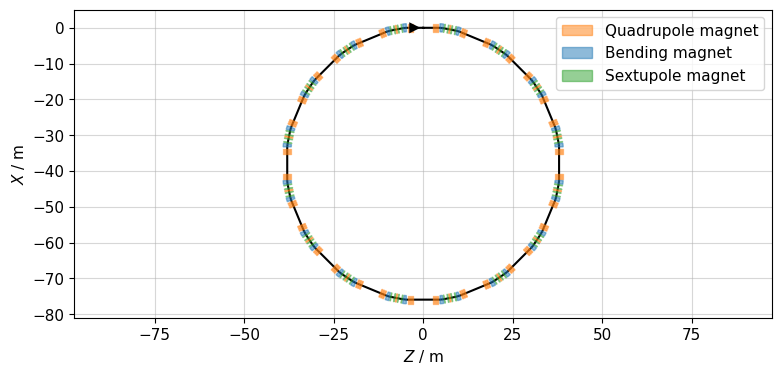

In [7]:
survey.plot()

In [8]:
tw_natural = ring.twiss4d()
np.testing.assert_allclose([tw_natural.qx, tw_natural.qy],
                          [qx_target, qy_target], atol=1e-6, rtol=0)
display(pd.Series({
    'Circumference [m]': circumference,
    'Qx': tw_natural.qx,
    'Qy': tw_natural.qy,
    'Natural chromaticity x': tw_natural.dqx,
    'Natural chromaticity y': tw_natural.dqy,
    'Momentum compaction': tw_natural.momentum_compaction_factor,
}, name='Bare ring'))

Circumference [m]         240.000000
Qx                         17.840000
Qy                          6.820000
Natural chromaticity x    -26.108723
Natural chromaticity y    -26.114583
Momentum compaction         0.000727
Name: Bare ring, dtype: float64

## 5. Correct chromaticity with two sextupole families

Chromaticity is $\xi=dQ/d\delta$, where $\delta=(p-p_0)/p_0$.
We target $\xi_x=\xi_y=+1$ for the full ring. At the ideal on-momentum closed orbit,
sextupoles do not change the linear focusing, so the quadrupole match is preserved.

In [9]:
chromaticity_match = ring.match(
    method='4d',
    vary=xt.VaryList(['ksf', 'ksd'], step=1e-3, limits=[-200, 200]),
    targets=xt.TargetSet(dqx=1.0, dqy=1.0, tol=1e-5),
)
chromaticity_match.target_status()
chromaticity_match.vary_status()
tw_corrected = ring.twiss4d()
np.testing.assert_allclose([tw_corrected.dqx, tw_corrected.dqy], [1, 1], atol=1e-5, rtol=0)
np.testing.assert_allclose([tw_corrected.qx, tw_corrected.qy],
                          [qx_target, qy_target], atol=1e-6, rtol=0)

display(pd.DataFrame({
    'Natural': [tw_natural.dqx, tw_natural.dqy],
    'Corrected': [tw_corrected.dqx, tw_corrected.dqy],
}, index=['ξx', 'ξy']))

Optimize - start penalty: 38.34                         



Optimize - end penalty:  9.53019e-07                            


Target status:               
id state tag tol_met       residue   current_val    target_val description                      
0  ON    dqx    True  -9.53019e-07      0.999999             1 'dqx', val=1, tol=1e-05, weight=1
1  ON    dqy    True  -2.43139e-10             1             1 'dqy', val=1, tol=1e-05, weight=1
Vary status:                 
id state tag met name lower_limit   current_val upper_limit val_at_iter_0          step        weight
0  ON        OK  ksf         -200       84.2684         200             0         0.001             1
1  ON        OK  ksd         -200      -144.366         200             0         0.001             1


,Natural,Corrected
ξx,-26.108723,0.999999
ξy,-26.114583,1.000000


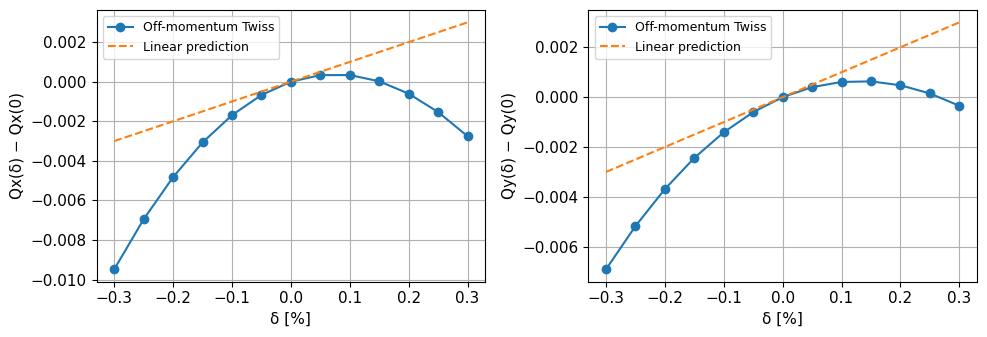

In [10]:
# Small momentum offsets probe local chromatic behaviour, not momentum acceptance.
deltas = np.linspace(-0.003, 0.003, 13)
tune_scan = np.array([[tw.qx, tw.qy] for tw in
                      (ring.twiss4d(delta0=delta) for delta in deltas)])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for j, (ax, tune, chrom, plane) in enumerate(zip(
        axes, [tw_corrected.qx, tw_corrected.qy],
        [tw_corrected.dqx, tw_corrected.dqy], ['x', 'y'])):
    ax.plot(100 * deltas, tune_scan[:, j] - tune, 'o-', label='Off-momentum Twiss')
    ax.plot(100 * deltas, chrom * deltas, '--', label='Linear prediction')
    ax.set(xlabel='δ [%]', ylabel=f'Q{plane}(δ) − Q{plane}(0)')
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 6. Add RF focusing

Choose an integer harmonic number $h$ that places $f_\mathrm{RF}=h\beta_0c/C$
near 500 MHz. The toy cavity voltage is 1.5 MV, set by `rf_voltage`.

With positive momentum compaction, the no-radiation stable phase in the Xsuite
cavity convention used here is `phase = π` (radians). The cavity energy kick uses
the magnitude of the reference charge. Radiation will shift the synchronous
particle away from this zero-energy-gain phase so that the RF restores its loss.

In [11]:
beta0 = float(ring.particle_ref.beta0[0])
f_rev = beta0 * c / circumference
harmonic_number = int(round(500e6 / f_rev))
ring['rf'].frequency = harmonic_number * f_rev
ring['rf'].voltage = rf_voltage
ring['rf'].phase = np.pi

tw_6d_no_rad = ring.twiss(method='6d')
assert tw_6d_no_rad.qs > 0
print(f'Revolution frequency: {f_rev / 1e6:.4f} MHz')
print(f'Harmonic number: {harmonic_number}')
print(f'RF frequency: {ring["rf"].frequency / 1e6:.4f} MHz')
print(f'No-radiation synchrotron tune: {tw_6d_no_rad.qs:.5f}')

Revolution frequency: 1.2491 MHz
Harmonic number: 400
RF frequency: 499.6541 MHz
No-radiation synchrotron tune: 0.00639


## 7. Resolve the magnets and check convergence

Radiation integrals depend on the optics **inside** the bends. A table containing
only magnet entrances may be too coarse. We make independent copies of the
matched ring, subdivide the bends into 4, 8, 16 and 32 thick slices, and compare the
computed emittance. Quadrupoles and sextupoles get two thick slices each.

The copies retain the magnet-family expressions but have independent environments.
The design ring remains available for further matching. The final, finest copy is
used for the radiation calculations below. This short scan checks discretization;
it does not measure the accuracy of the idealized physical model.

Subdividing a thick sextupole also changes its numerical integration. We therefore
rematch the two chromaticities on the final sliced copy, so the radiation model
also has the requested chromaticities. This leaves the ideal on-momentum linear
optics and radiation integrals unchanged within numerical precision.

In [12]:
convergence_rows = []
for n_slices in [4, 8, 16, 32]:
    candidate = ring.copy()
    candidate.slice_thick_elements(slicing_strategies=[
        xt.Strategy(slicing=None),
        xt.Strategy(slicing=xt.Uniform(n_slices, mode='thick'), element_type=xt.Bend),
        xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Quadrupole),
        xt.Strategy(slicing=xt.Uniform(2, mode='thick'), element_type=xt.Sextupole),
    ])
    tw_candidate = candidate.twiss4d(radiation_integrals=True)
    convergence_rows.append({
        'Slices / bend': n_slices,
        'εx [nm]': 1e9 * tw_candidate.rad_int_eq_gemitt_x,
        'σδ [10⁻³]': 1e3 * tw_candidate.rad_int_sigma_delta,
        'U0 [keV]': 1e-3 * tw_candidate.rad_int_energy_loss,
    })
    radiation_ring, tw_integrals = candidate, tw_candidate

convergence = pd.DataFrame(convergence_rows).set_index('Slices / bend')
display(convergence)
last_change = abs(convergence['εx [nm]'].iloc[-1] / convergence['εx [nm]'].iloc[-2] - 1)
print(f'Change in εx from 16 to 32 slices: {100 * last_change:.4f}%')
assert last_change < 0.002
np.testing.assert_allclose([tw_integrals.qx, tw_integrals.qy],
                          [qx_target, qy_target], atol=1e-5, rtol=0)

# Restore the chromaticity targets after changing the integration of thick sextupoles.
radiation_ring.match(
    method='4d',
    vary=xt.VaryList(['ksf', 'ksd'], step=1e-3, limits=[-200, 200]),
    targets=xt.TargetSet(dqx=1.0, dqy=1.0, tol=1e-5),
)
tw_integrals = radiation_ring.twiss4d(radiation_integrals=True)
np.testing.assert_allclose([tw_integrals.dqx, tw_integrals.dqy],
                          [1, 1], atol=1e-5, rtol=0)

Slicing line:   0%|          | 0/465 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/465 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/465 [00:00<?, ?it/s]

Slicing line:   0%|          | 0/465 [00:00<?, ?it/s]

,εx [nm],σδ [10⁻³],U0 [keV]
Slices / bend,,,
4,15.786594,0.698734,170.673866
8,15.514387,0.698760,170.673866
16,15.446191,0.698767,170.673866
32,15.429133,0.698768,170.673866


Change in εx from 16 to 32 slices: 0.1104%


Optimize - start penalty: 0.05843                         



Optimize - end penalty:  1.81973e-07                            


## 8. Connect radiation integrals to equilibrium

For this planar, uncoupled ring, write

$$I_2=\oint\frac{ds}{\rho^2},\qquad
I_3=\oint\frac{ds}{|\rho|^3},\qquad
I_5=\oint\frac{\mathcal H_x}{|\rho|^3}\,ds,$$

$$\mathcal H_x=\gamma_xD_x^2+2\alpha_xD_xD'_x+\beta_xD_x'^2,
\qquad \gamma_x=\frac{1+\alpha_x^2}{\beta_x}.$$

For the sector-bend model used here,
$I_{4x}=\oint D_x\rho^{-1}(\rho^{-2}+2k_1)\,ds$; there are no additional
pole-face terms. With no vertical dispersion, the partition numbers are
$J_x=1-I_{4x}/I_2$, $J_y=1$, and $J_\epsilon=2+I_{4x}/I_2$.
The equilibrium predictions are

$$\epsilon_x=C_q\gamma_0^2\frac{I_5}{J_xI_2},\qquad
\sigma_\delta^2=C_q\gamma_0^2\frac{I_3}{J_\epsilon I_2},\qquad
U_0=\frac{C_\gamma}{2\pi}E_0^4I_2.$$

Here $C_q\simeq3.832\times10^{-13}$ m; with $E_0$ in GeV and
$C_\gamma\simeq8.846\times10^{-5}$ m/GeV³, $U_0$ is in GeV.
The amplitude damping times are $\tau_i=2E_0T_0/(J_iU_0)$.

Reducing $\mathcal H_x$ **where the beam bends** reduces quantum excitation.
Zero dispersion at a source point is useful, but alone does not imply a small
natural emittance. The Lorentz factor $\gamma_0$ and Twiss $\gamma_x$ are different quantities.

In [13]:
I2 = tw_integrals.rad_int_i2
I3 = tw_integrals.rad_int_i3
I4 = tw_integrals.rad_int_i4x
I5 = tw_integrals.rad_int_i5x
J = np.array([1 - I4 / I2, 1.0, 2 + I4 / I2])
gamma0 = float(ring.particle_ref.gamma0[0])
Cq = 55 / (32 * np.sqrt(3)) * hbar / (m_e * c)
Cgamma = 8.846056192e-5  # m / GeV^3

emit_formula = Cq * gamma0**2 * I5 / (J[0] * I2)
sigma_delta_formula = np.sqrt(Cq * gamma0**2 * I3 / (J[2] * I2))
loss_formula_eV = Cgamma / (2 * np.pi) * (energy_eV / 1e9)**4 * I2 * 1e9
tau_integrals = 2 * energy_eV / (J * tw_integrals.rad_int_energy_loss) / f_rev

# Independent geometry checks for equal, pure sector bends.
rho = env['l_bend'] / env['theta_bend']
np.testing.assert_allclose(I2, 2 * np.pi / rho, rtol=1e-5)
np.testing.assert_allclose(I3, 2 * np.pi / rho**2, rtol=1e-5)
np.testing.assert_allclose(emit_formula, tw_integrals.rad_int_eq_gemitt_x, rtol=1e-5)
np.testing.assert_allclose(sigma_delta_formula, tw_integrals.rad_int_sigma_delta, rtol=1e-5)
np.testing.assert_allclose(loss_formula_eV, tw_integrals.rad_int_energy_loss, rtol=1e-4)
assert np.all(J > 0)

display(pd.Series({
    'Bending radius [m]': rho,
    'I2 [1/m]': I2,
    'I3 [1/m²]': I3,
    'I4x [1/m]': I4,
    'I5x [1/m]': I5,
    'εx [nm]': 1e9 * emit_formula,
    'σδ': sigma_delta_formula,
    'U0 [keV]': loss_formula_eV / 1e3,
}, name='Radiation-integral prediction'))
display(pd.DataFrame({'Partition number': J, 'Amplitude damping time [ms]': 1e3 * tau_integrals},
                     index=['x', 'y', 'longitudinal']))

Bending radius [m]      4.329014
I2 [1/m]                1.451412
I3 [1/m²]               0.335275
I4x [1/m]               0.009313
I5x [1/m]               0.005246
εx [nm]                15.429133
σδ                      0.000699
U0 [keV]              170.669668
Name: Radiation-integral prediction, dtype: float64

,Partition number,Amplitude damping time [ms]
x,0.993584,16.050848
y,1.000000,15.947861
longitudinal,2.006416,7.948431


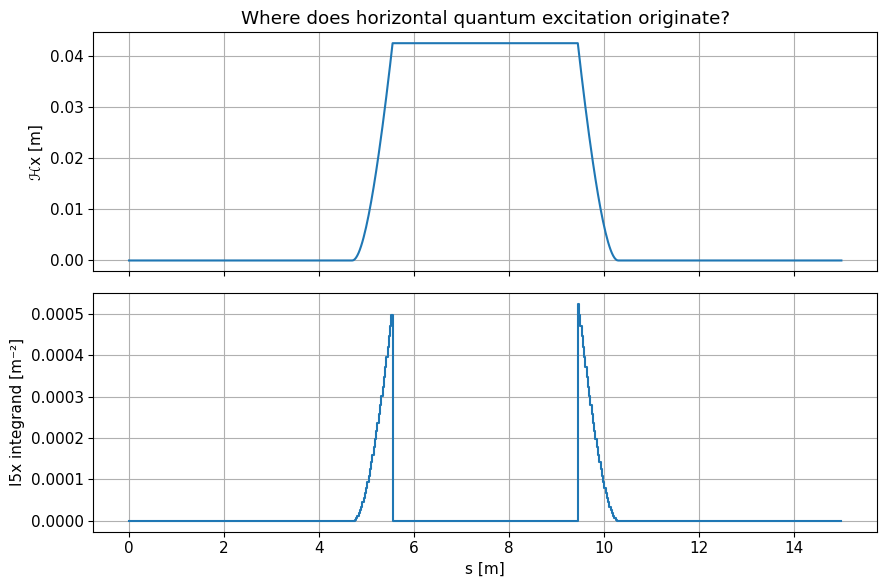

In [14]:
# Examine the radiation integrand over the first cell.
first_cell = tw_integrals.s <= cell.get_length() + 1e-9
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 6))
axes[0].plot(tw_integrals.s[first_cell], tw_integrals.rad_int_curly_hx[first_cell])
axes[0].set(ylabel='ℋx [m]', title='Where does horizontal quantum excitation originate?')
axes[1].plot(tw_integrals.s[first_cell],
             tw_integrals.rad_int_i5x_integrand[first_cell], drawstyle='steps-post')
axes[1].set(xlabel='s [m]', ylabel='I5x integrand [m⁻²]')
fig.tight_layout()
plt.show()

## 9. Solve the 6D equilibrium with radiation

Enable the mean energy loss and compute a damped periodic solution.
`radiation_analysis=True` adds damping rates and equilibrium emittances from the
linear radiation analysis. Although mean-mode **tracking** has no random photon
kicks, this **analysis** includes quantum diffusion when calculating equilibrium.
See [Xsuite's radiation guide](https://xsuite.readthedocs.io/en/latest/synchrotron_radiation.html).

The RF voltage must exceed the energy loss per turn (in eV for a singly charged
particle). The 6D closed-orbit solver finds the synchronous longitudinal offset.
We do not taper the magnets here: their strengths stay at the nominal design
values, so the energy sawtooth can slightly alter the orbit and optics.

In [15]:
assert radiation_ring['rf'].voltage > tw_integrals.rad_int_energy_loss
radiation_ring.configure_radiation(model='mean')
tw_rad = radiation_ring.twiss(method='6d', radiation_analysis=True)
assert tw_rad.qs > 0
assert np.all(tw_rad.damping_constants_s > 0)
assert tw_rad.eq_gemitt_x > 0
assert tw_rad.eq_gemitt_zeta > 0

comparison = pd.DataFrame({
    'Radiation integrals': [tw_integrals.rad_int_energy_loss / 1e3,
                           tw_integrals.rad_int_eq_gemitt_x * 1e9,
                           *list(1e3 * tau_integrals)],
    '6D radiation analysis': [tw_rad.energy_loss / 1e3, tw_rad.eq_gemitt_x * 1e9,
                             *list(1e3 / tw_rad.damping_constants_s)],
}, index=['U0 [keV]', 'εx [nm]', 'τx [ms]', 'τy [ms]', 'τε [ms]'])
comparison['Difference [%]'] = 100 * (
    comparison['6D radiation analysis'] / comparison['Radiation integrals'] - 1)
display(comparison)
print('6D partition numbers:', tw_rad.partition_numbers)
print(f'Synchrotron tune with radiation: {tw_rad.qs:.5f}')
np.testing.assert_allclose(tw_rad.energy_loss, tw_integrals.rad_int_energy_loss, rtol=0.01)
np.testing.assert_allclose(tw_rad.eq_gemitt_x, tw_integrals.rad_int_eq_gemitt_x, rtol=0.01)

,Radiation integrals,6D radiation analysis,Difference [%]
U0 [keV],170.673866,170.673842,-0.000014
εx [nm],15.429133,15.429328,0.001261
τx [ms],16.050848,16.050820,-0.000173
τy [ms],15.947861,15.948071,0.001314
τε [ms],7.948431,7.948457,0.000329


6D partition numbers: [0.99358557 0.99998698 2.0064099 ]
Synchrotron tune with radiation: 0.00637


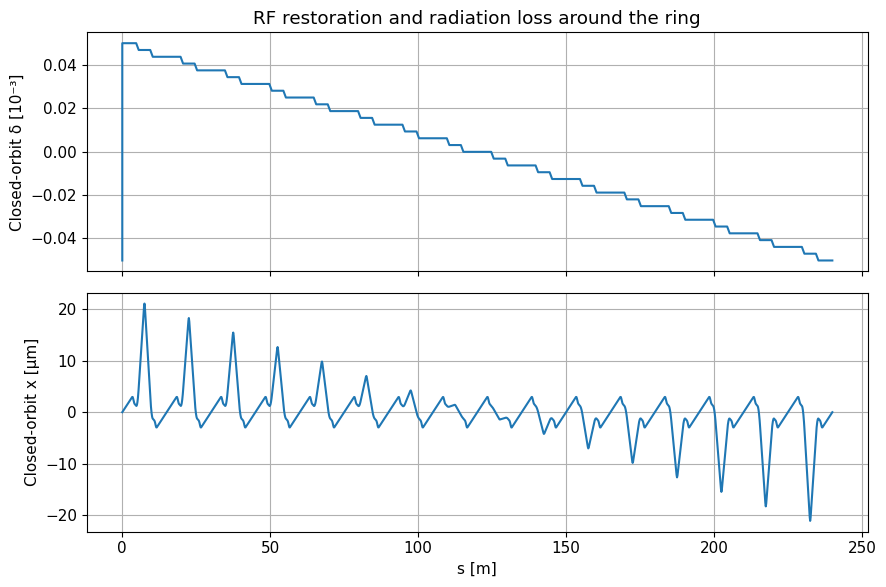

In [16]:
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 6))
axes[0].plot(tw_rad.s, 1e3 * tw_rad.delta)
axes[0].set(ylabel='Closed-orbit δ [10⁻³]', title='RF restoration and radiation loss around the ring')
axes[1].plot(tw_rad.s, 1e6 * tw_rad.x)
axes[1].set(xlabel='s [m]', ylabel='Closed-orbit x [µm]')
fig.tight_layout()
plt.show()

## 10. Equilibrium beam sizes at a source point

In an uncoupled approximation, $\sigma_x^2\simeq\beta_x\epsilon_x+D_x^2\sigma_\delta^2$.
Use the full 6D covariance to include the dispersive contribution consistently.
At these energies $p_\zeta=\Delta E/(\beta_0p_0c)$ and $\delta$ agree to linear order,
so `sigma_pzeta` gives the small-amplitude momentum spread.

The first row is the RF / straight centre. The ideal planar model has essentially
zero vertical equilibrium emittance: it contains neither coupling nor vertical
dispersion, and the radiation model neglects the photon opening-angle contribution.
Do not interpret that as a prediction of a zero-height real beam.
For an illustrative vertical beam size we also evaluate **an assumed**
$\epsilon_y=0.01\epsilon_x$, leaving the horizontal emittance fixed.
This is a beam-size assumption, not a calculation of coupling or emittance sharing.

Natural εx [nm]                              1.542933e+01
Ideal-model εy [nm]                          6.606393e-49
σδ at source                                 6.988162e-04
Bunch length σz [mm]                         3.046037e+00
Horizontal source size σx [µm]               1.360706e+02
Assumed εy [nm]                              1.542933e-01
Vertical source size with assumed εy [µm]    2.230439e+01
Name: At the first straight centre, dtype: float64

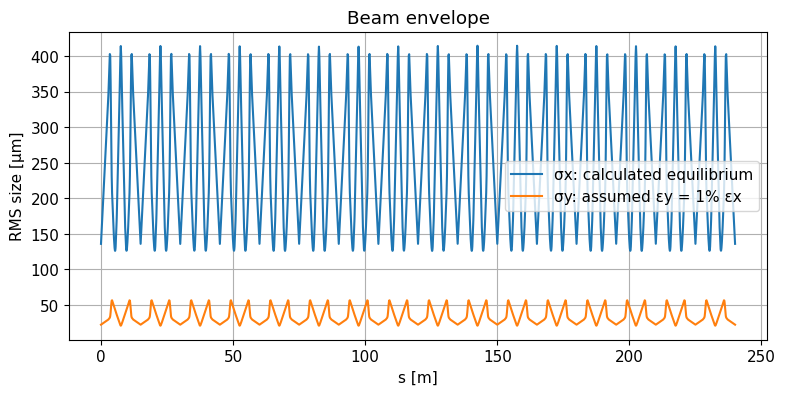

In [17]:
cov_equilibrium = tw_rad.get_beam_covariance(
    gemitt_x=tw_rad.eq_gemitt_x,
    gemitt_y=tw_rad.eq_gemitt_y,
    gemitt_zeta=tw_rad.eq_gemitt_zeta,
)
assumed_emit_y = 0.01 * tw_rad.eq_gemitt_x
cov_illustrative = tw_rad.get_beam_covariance(
    gemitt_x=tw_rad.eq_gemitt_x,
    gemitt_y=assumed_emit_y,
    gemitt_zeta=tw_rad.eq_gemitt_zeta,
)
display(pd.Series({
    'Natural εx [nm]': tw_rad.eq_gemitt_x * 1e9,
    'Ideal-model εy [nm]': tw_rad.eq_gemitt_y * 1e9,
    'σδ at source': cov_equilibrium.sigma_pzeta[0],
    'Bunch length σz [mm]': cov_equilibrium.sigma_zeta[0] * 1e3,
    'Horizontal source size σx [µm]': cov_equilibrium.sigma_x[0] * 1e6,
    'Assumed εy [nm]': assumed_emit_y * 1e9,
    'Vertical source size with assumed εy [µm]': cov_illustrative.sigma_y[0] * 1e6,
}, name='At the first straight centre'))
np.testing.assert_allclose(cov_equilibrium.sigma_pzeta[0],
                          tw_integrals.rad_int_sigma_delta, rtol=0.02)

fig, ax = plt.subplots()
ax.plot(tw_rad.s, 1e6 * cov_equilibrium.sigma_x, label='σx: calculated equilibrium')
ax.plot(tw_rad.s, 1e6 * cov_illustrative.sigma_y, label='σy: assumed εy = 1% εx')
ax.set(xlabel='s [m]', ylabel='RMS size [µm]', title='Beam envelope')
ax.legend()
plt.show()

## 11. Exercises and design studies

1. **Retune the ring.** Change the tune targets to $(17.88, 6.76)$ and rerun from
   the beginning. Inspect matching residuals, natural chromaticities, sextupole
   strengths and equilibrium emittance. Why do the sextupoles need rematching?
2. **Change the source-point beta.** Try `beta_x_straight = 1.2, 1.5, 1.8` m,
   rerunning from the beginning each time. Compare emittance, the resulting vertical
   beta, source sizes, maximum beta and sextupole strengths. A smaller horizontal
   source size need not mean a smaller emittance or a better beam envelope.
3. **Change energy.** Try 2 and 3 GeV while keeping geometry and normalized magnet
   strengths fixed. Check $U_0\propto E^4$, $\epsilon_x\propto E^2$ and
   $\sigma_\delta\propto E$. At 3 GeV the loss is about 1.66 MeV, above the
   default 1.5 MV RF voltage: set `rf_voltage = 3e6` before the 6D calculation.
   Keeping `k1` and `k2` fixed at a different energy requires changing magnet fields.
   Compare emittances at the same energy: this toy's 15.4 nm at 1.7 GeV corresponds
   to roughly 48 nm at 3 GeV before any further optics optimization.
4. **Raise the RF voltage.** Try `rf_voltage = 3e6` at 1.7 GeV. Compare synchrotron
   tune, bunch length, transverse emittance and energy spread. Which quantities
   are set mainly by the magnetic lattice?
5. **Extend the convergence study.** Add 64 slices per bend. Compare the radiation
   integrals and the 6D result. Explain why agreement to machine precision is not
   required even when each method has converged.
6. **Go beyond linear optics.** On a separate copy, track particles with increasing
   transverse amplitudes and momentum offsets. Measure survival over a stated turn
   count and inspect tune footprints. The small Twiss momentum scan above is not a
   dynamic-aperture or lifetime calculation. Borrowing another ring's tunes does
   not establish the nonlinear acceptance of a different lattice.

For a tracking extension, `model='mean'` damps particles towards the closed orbit;
`model='quantum'` adds stochastic photon emission. Compute Twiss and prepare
initial conditions before switching to quantum mode. Demonstrating equilibrium
requires many particles and several damping times, not a few turns.

## 12. Save and continue

`ring` is the unsliced, matched design with RF and radiation off.
`radiation_ring` is its independent, sliced copy with mean radiation enabled.
Their variable systems are independent: later edits to `env` affect the design
ring, but do not update the already-created radiation copy.

The optional lines below export the two models in Xsuite JSON format. They are
commented so rerunning the tutorial does not overwrite a saved design.

In [18]:
# ring.to_json('light_source_design.json')
# radiation_ring.to_json('light_source_with_radiation.json')
# Reload, for example: restored_ring = xt.load('light_source_design.json')
print('Tutorial completed: matched DBA ring, chromaticity correction and radiation equilibrium.')

Tutorial completed: matched DBA ring, chromaticity correction and radiation equilibrium.


## References and model provenance

- [Matching guide](https://xsuite.readthedocs.io/en/latest/match.html): knobs, targets and residual inspection.
- [Synchrotron radiation guide](https://xsuite.readthedocs.io/en/latest/synchrotron_radiation.html): radiation analysis, tracking modes and tapering.
- [Line API](https://xsuite.readthedocs.io/en/latest/line_api.html): `twiss`, `match`, slicing, survey and radiation configuration.

The code builds its own teaching lattice; the documentation links describe the Xsuite interfaces used here.

- [BESSY II lattice design (1993)](https://proceedings.jacow.org/p93/PDF/PAC1993_1474.PDF): reference energy, circumference, cell count and nominal tunes.
- [BESSY II straight-section optics (2011)](https://accelconf.web.cern.ch/ipac2011/papers/thpc155.pdf): representative high- and low-beta source points.

The toy borrows these reference scales and a source-point beta target. Its uniform
cells, magnet lengths and strengths, RF voltage, and predicted emittance belong to
this tutorial; they are not an operational BESSY II model.